In [1]:
import os, zlib, base64
import pandas as pd
import numpy as np

if not os.path.exists("diabetes.csv"):
    with open("diabetes.csv", "wb") as _f:
        _f.write(zlib.decompress(base64.b64decode("eNptXMuubbdxnBvwn2wckM33MEaQwIMgBpIfSOQL+8LKFSBZ/x92VXcvcp8zsCFpn/Ui+1FdXc1///n3n3757dvrTz//8stf//Lrt99++/3Xb6//+sf3H//99+8//ePH/g+vP//47fefv/94/ek//vz61+//87/f/vntt798++v3v/367du//f7jp39+/+XH61/+9u31n7//86df/u/bH/+Q63wNeZX2yn19tFcpH/2VPrqMV0uv/Mc/zPbq/SXrlZPs36Xj99Lyq+RX2jeY5dXrq4jdQMpH0RvoTQU3WLhBea36kvmxL/rIfbyEV5fxqomPn69a9s/yIXPu99Brc+6vsS8b/vSGp0vaT096/Zj6mvtBeoneWvb3SOe17TXSc21peLFcqn6NPnsN/YPaXq2Wfb/9N/vntu/IZ0t7rf58WKm4XvZ/aJUPSK8lxwMGXi4vfzn9pHEsTZn757a/uPD6sl7zeEEZ++vzR6351QaXdi9d0qWbtesL6geWtV9w4fq9rHuV8/6XgaXB7efeuIyfU9pP18fG8/dbfdRZbWNynvvGr7r3ougy8HpuLK4f19vL4trvj/c/0FXTr9omULntag1761Is//4DXcSKa9teeHv23qO9ZftTZe99Wbh4JGz1vngtfbNz66p++sRuY+v6a6XjyxZevu6Xr3y3jLUNs9Yd/5BeYMhq9TBHNTJd2R5fZksnNJ1tR/srSsbCS2p+871ko19Pr7h+2zJMZxvW3pt9aa66fR+Cdd/rLHj5bXGT+7YtSAQ/i5ohdz2P26wq913tZuIP0nrphnf/Ayzt/o7OtdkWrG+3fa7i5fXnuT9MJtxxr+H+h6xGLBXLJt1fbT/3fHReHwubOvVivff+swFPC5PFw7OoGyXaxH4NXVi9kS7L2kthJlHwZs+X2cog/OBiwZsPX1fB43vfCw+X3luuUeLxJ1zf9jP1nrp0WT1CLXobb6E/bS9rDAjbIHak4t4W7NjIuox4tXJZXE24dV94Hbxb16XZLmNfLh8D0WD/LZdm3wv7qcsKd9InDMkeLbbT9np5O15hm2Hlvunr7cct+zr9zI+5ir4wjK7rdzzXL7xA6x7O9vPPcCeMBt2NTjfmtllYVX28+S1cWrjZ/1m3kXfYr7iXGMaLt6871vn9MxJGo+FxY/bacnm3AWkOUG/XH+HMuu388EFn3m+S1HTwXXXbZJtcOKyL/jn+h59Hhh3oZxc8N/lnF08Clp2Gmsxe1LKDy7aIYY5eI0bquyVsXe1wh9XFc9te8ymXVey9+Bhzhxlbk6abqjfbb1MzU8h+JS7Ktqgvl7RG9isvy5Onwe8LCsLUfkiXM/tZgC+0WU0UE8lkb7bQ4PoOnbZfud47LnT2Rg9CkL1yKx6tMV08ymhSTc/lDYEEeSzzD85gUekRE/kUwQTIIRf8PZNHKfA/X9rGq5PiAgaaZQlA/6NaTGKYx69Tw9T0zKmYwwLsxL1rDmeWOzvs3FSxcsW+PO9vnbi7aChojO8F5qkmhfha3KR0PXYUeTxpqMtLWBwtcq82f+8Ikc+mC798ITVxWXTPy4Ma9PIdZezL92vcabsyTO6fHdgI1kZOsyj7rXzfi1pnLk+kquf7jS+NUmOvGW3B+29skTXIIDH3sLnt5h3BJT4eqbNEctPonebx9pNmp0Y9HDYNBC1Ns0XMbGfsPFCNBk3LbkRV+508xSALaBjPmgLw9Rp1LZB3hHeBRyMFKKgrlpl18/pE7nU4C5ftHuV2hGvtyoDZnMZcVhgF90+EANvwFD3y4qxLp9F/ajBBrOnZApUCz9PZNy7AwoyB+KMuIQitE3nC4ty+3B5ccblagSg8ZqRozbLH9kQNFb4vlvZzsc/aS7XfKTP/JgZg8TC1EEILs+OkObZuzqApfzuT4odt8pVZp+jOMYL2txC2V3ZvtjiA39f1Myt1bsh2MbMXouznDxhmRD8m+5piUdTTDahN/ywtTo7dKowyq7gtCXPmfqcm/mkz+ZLu5+rXnc9GSk7hi3vNG7AP4sziq81hmGC/RiMYml4dFM1+zdx8wjeLQgjeuMJHM8GCBYECHATszNCNVWvYzZ31ViNU0RKFIGjHSLU8zWa6zYIrxUNXvzIGLtXQY0F3b0UjpEeA+2BCmZZuNCavcy9596bR1nBxvQsafJVYQlDTnxe60+XuzUP+GlbNOED5cO8xM8SHbc9SW7OYpzZK8+/Ahorktv83/jw2pjJ0tIO/ZoT1gGZc3wO8sJhJuNyK3KqJ2JCp3KUYkUDeSaIvD6oX5OeWiUbKYrBai6jtK0sDiEKj7vF6+w0rId3symRWW8CfDES+zQQVCe/bPRdpNaDwe9tFxWfh3jtL1+SobZ5F2sDdx041nalug5H98B39tRo10Fj27c0/99K39+/a9U6u/gcDYQHxPZ6v0aGQHaBBeD2ww3HBxwHB0MU03O7X3TvFOqrXEXm6wSIS3KswHiar5K2ARRWG6MTydDlzsFBoaPQIz25FIqrcpbVZ8kjFa/+ELIx6FDkG8EPNyeqceSVxe3XZ39KaZ6kpB0bw2NCjSNt/ChfuxbFT2TvtGGK+YzPWI+IIpQH6KSTB9jJV6C6UqJTa40uWxNvwqLk3QMvfA4Rgbfd21OzvbwgqL0aCvF+BaQz17WdPFs1M9GRsTD5KmYKdawECQNs03dvq0a/cyLRdqwuX2Mthxda2L8Vn23KaES8Z4NAXp+jiK+KeAOVgrGYszsTmPQiEPgGqyZIS+CIFSfgD5RRYX3fDxfsPdhxa1fFNL0FYJZST+1/UmTfoVrua21f47AnGZy9pKwaoJTIdM6XWCllrPmLavYh1eKZcYFOu+k7rQ4deovdWv0+AjQhwe30NFu2bTlRRoovC+Aei7QHU9Yi+HgkC2Gxbm/MK/h2RpDhlk+DrWgEjpzLQiAQpwhqvPSYHj2iBm4W47Shg8YC9oGZ2mZj/cFqYBXAo/wBLlAmwp1WgLVwa8OlguyyG27YCfzH/lOSUUqtilNAc/qtnJ3zfKJa9Brg42Jwi8gaOc3rabcRswI7LAb2xHlpO0K8LahnWr8tea2/W5WuMVIX2baGMxSmu70S0ZV9v2aWW6wYVeHapVWFX070oxLOrdUPjc9yJj4k1MackEmkdu75QfHPTW8QhpFXBwolV1+rn2Urz/jmpSg+oX/NdgZJNkhqUyDb+TvzFt2+W3YKJ2+iwY4MBlBgFe26OqPeVCyxjo2Vv4BqZLxFHLbij5c0ebEh5+MPkvqBp84AbN3IE3K5ylAnKLVdL6tizEd/V1h3+DZEreWq22t6KwCaIsY31Be1Gje2oQlHlle5208juKthNTlEWeosBh3Z6YzX+9gl0AxCiANQZExdwR1dPiY+qeKeQRlyphU1O23lNeSVZdvVHZ5ZQwV/q4szxkCLznXRhed49OWvyPAtwpp+huDyAJO5fqxc7ytN5IIyCZaWovum6KSjEp8BloVWfmmDn0IGaQpBhGQkS2NtMnKqR8tlbPkHDeyPt0o0H1Pc1mDtX8FUVeK48Fk/A5RY/WU/J8+30uaBVhpYdUT1XJv4ygsXb0Wi1A7F5oqhOH2/z6txIAFoiZQUi1ckHCyjjhNlmtw0kpBZLWnFmPHxUOSijzoShyMs6Drm6VykeJOUkyboV3QORxklQGEHoa5359DLk9qhhsSYaAiyzRQPjZD8ifyTipUxvuRoKRpsncliMgxe92iz/Lscs+yud+QYnNQ2U9HwQWlrdaGVNVNGDH3XAVcR7Jcq0PNTqRZs3WtSajqP3mjausX88yOsmvmnsdBUl/BRO7Ot3ONEtyFFjaJRT1FKbZYBAa0pLHEtbwddUYD1Lq4SaZYBCxbKUadXqIBBvqCBa8HAOCeSCBAW2voLR9uhfDzjkSMtL6IMlg6WOSIzbVSaCipbHljqUELcejzoCN9Q+i8ljdg9xvfr1J56Ye5kOQHTsS572eeJdrGyoIABPFOvZfh/RvGSOqDXgkvYtzsquWc0qvvCKMhkK8BZsduRonVbEKc1gmoJYbOueG1rSQNPAY3lvcPsTC7X8xc4QloA8tnq8wWF2ilfKjNmpSmBwAdgqWqeKgy3RwFE9yu6FDhrOScgau7vrkyZfwKIDFZ39GnQ7ZEb/MCHDEI9VI1/coCdq0iKPO00zWeMpQKWpuU6HJEuQTCx5WeF09suVnrFIoq21fjARVpppSZyi+plHCGfxmtQsGMPJx2WFaNh3pN4WEXz/07DiKHnBXrbnml0vQCLd2JI898oKkF3zV11h8IxIYKs5f+ownphKznBAAtT/AMurda4Bn361NFAE0RCR/FhD9OFLtxbqMu8P3u/WYVerRBdMwI5WCXCglWHKQfPIZTZCaj+NqHLUK65HCDO4EsiWo2Ca0YSsDalCgZUnsWlfqJGc0RINmHx0SA9A7Q2n5E06NLHr0f4M0Jj6Tc1bdiV0eBiR/S/aak5WhAy3m4QWsHhZa9y2rB6Yr3oNmBEx2DMPEizXG44b2lcSdATw0pV/gfeinmLOyFM1qHdPQ8t7PtPbLma5EhFZplFFaMHScNtjVj04gZ6vNGSYWeOQFdD77WY6NxZrtwx2GScBXAN4QyaqZfepCTjbKlgsMJf5qUzRLyqLHHgzbDBtXRd5yQGSi1miRD8iQV+jRRrMOZsOgbXhXsaJuyj/1Y0FqTcCL2iXWBtktHF4giKZ/e1aKzIMABBl/7kic2Z0mGkr7AdkrmZLnygYNVRSPCDuQUABixGGdnBt515r7ZUYfZVAMTtTcQeSuGRsFMi5CCBqxIi1moPsu6oqCKK7NeSqSLHaYOJhB+M9SDD5TDR5mfrwx86uE8rBzbBy22EmQCiEByQJWncNgvI+86q7luE8iXb0mfUlW8vAzFSSaxgSym0yZ0FSdERnkBD6Pta96m7Dhe0pZXunyzNyDRJcpnevZnLWzuh9o+cJmFSr4l1Ta2WitdX7Q1kKoVrRnH+GH331Or1i1MrG3LsBgas6pXsnppZHeuF9+Nm8U9KlR2hahjCPQn4HVQlKLoslRQUrpnjJzZxoLVMeKBPBliRoUdNNyN2UoK2X+tSbzYUV6mYmQWtuyfuBJ1so5HY0VpnMSsD8aALUKojpoqG2pcGIdxbOykEh97Mrgyy3J5zqOqrudCShlHoMSZKxb/6szGgXXGG7OTLODglWx6AtyseLt8iA5Lg8MHKm8yXuK2O9q+Rg0CF7IfjvCAO12dqMoAEcLaBuo7lKXJynC9TclSFw2/5RvexRjQegnhFjuYfNzPS5EV4MRrp8o7+zV92Z3pAgpBcbLFbJSwDsDhylztWCJNZ8YYE7j3th2J5Y+21M+5Hb3RIyiFqLQ8VGsZT6TPZkroIe76zMq3VTlqXLKFkLafaCUGI4sA7vcSwWxBtQlACJowRZTN1LuzQMcx2F1+wX0jAagXmJGoXnZxqlsu0tGquTxKr2+q0Jv9NfXV67VMB7LfXm0wc0SvGGOe5xQeAvsASZ8pRsXfLYl5quNF8pY3I+c92NvGrqOuYm0ydc0kIvbLwd16FvehrpXj0Us1nVoIlGgwrGEw3Sab620k3F0qRbC3Znm9zFsRvvt53Myy50IxTVEiAX0yMdAKpatXYaTevLjI4NiMo+LxFaYWP24a6g0FL+mYqeEYFyUlZT2BSz7u8M0aQKC9NF4E/LfYb9U6E9HP14MQ1ZD9XPGWzNcvbi9xHKStBBWugb3Vxms71ZKIkFgtNC9n95FpA3dcUwynYG+GX6uPN2O2QGWpB2diBoz+mpxdEWcCFAtOPQe7Em62RnoOOj9ksiCjlbPA13z8V6MCPA25MJyslfGSVWW2BA0LT7ocyLbCk1D5GCckcTBTrIjDA5iNIK8r/afi4T5U0T1i3wrBnI1+ms5RFigi7bnzCCT2opwsfOJKNdGp9iJTSpkVXYZ2fnQ+VX+SMp9d6iawB/QwuVtIo8NVy76+Pk7G/o0vabTcBeY5RWja4wvRMSaRR/mf2G5v3mwQIJQk2+tIQ6IsO8CGSEoFIe+aNJ0deNOrtXtvra+Ob+lq00FjaHpRMtYe3QUTqkpdx0JSKB4cyOIVaNfrTJ4fbDV6iOqnMhvV+JqBIhlOrQrNDytRmAaDs8F+T4MEQ0KJRJQ2mFMkJNPD9JFKfqBK3QQBLX+nkYH61vb1QKKiPNgDmEcqvWqPgylJ3pVthnSu00mMkdcNiFx6sHUzJOWGkOUh0Rr3bNJhRS3aFwL2Bnz4JXnKpv3sdmD2VOkpNo8LOKEK9iTsGVVrPTtf/3o60JHa0rQWcFf4BUka1I6gEuznDGdmQhdPJwJp8KuEd/BM735g8BuXU6gQFxALVtG2tDO+vUK6fINYmodN24s4/qNslCTVMR9EgkPyWcrVJRrXaSeHsl3MONtSJm2Mteiggb68YEdWu/jZgeYGXs8RaJqo7qbwa6Tlx+D3QcPRJt/aUVlQwd8VMWatWbouUiPzPJ0y41dGXUci/adSdEyFEi5mXDDRnzJezcJZe9sKlpWjx82CPySwDrzJImbICQKLtRMFUEtQhYJnF5y+aswjUHNsjRnZksdVRky3p1B0cnDNaXslBsicFxKqwSa08r0Wjv1rFceHPVKdmrg5DtroZj/c2uqsZF12Sut84KIZsCCdNUAAhm6IUNMWFKZZpeU39EVwxMZpNxMOijfRoegiZiebKYr0PK2kD0zUNf/VaAuEAwEFNFvXuKeat3sHNIadqFmYLkmSaKGwebaqaW69mGnfMTFB9P/TkXGo7S7ihaI9LMYgNYmJQi57hikTYgsrEESdGPjOIxzZvSY229WosBrWFwOIaEmF28vJyAxL2AjF8ARtWJGDBBuFj3n27Sm8+aqMmAJ9ValVBVS2Qrb6qp0oBXbQjFGyOSnGSOsS7NuNZqg4ftJL8QNLEaOfQM1Ii8h12oRGir2XoH1lQnPj0RxGnKpnqfBZHS8jgRrGl44L9rRnO2GeN3NRcky+FlrV6SiuFtRnl6G0oN6hAa0Td7UIlteU1n6liD42o7LOrgRg6BDKIqhHU01K54xHktlJ6tO8k5SrHCYnxKRviw7P1Nas5VGL28Khmgx1wzNQ9eylQgbQaNAEruSNNAk9FL0t59jzLZHh3AXnVo4KxLUN7SHcguGlA35MaebaDFL+fnMOE2XaM3GOYrOp+U4OVDPKzo27+rZhp4Gp5AyzAO9RqHyo9rrlsPZUr6tg6Z3Uqfgotkn5LL9R45simLRxX7VgybkkJ5rhYySTohcEMx7VIOZg0dUK2pcnJBe1VInJ0lUIOar6ePpb1qR3+klvLZwqv6zSWAJ2I6kowxpbU63BZ0C8rBW4nTbsv0AgQECqK57yjoptVc08jtGCOTEPFpBnsL/ESGPUBvaTaJJg2JFnU2hwh8PoUUs66eEeAl8vgonqYx2sa8o52K6fIVOQpVm3ld9WAs52dNvebE7rp0zmj0HkYt0f1E2/sRrhZrErneTMmXeRilGAfdXM7GIiqziQOT2i9fvRSe6cvpkhHkT3+b6LV54oRhJVcBnt7e7fVY59s4AKk3a63W6IBZ87IAhFjzT3WXrYXDEhKrjGA9bYMVg5cJvFP2gljZ8SjTDZB7phcfnYxiuzMa+CAE03R1eGWzh8t5nVG8mb664bK4t5fT1jVslyIqROLFi42JOSkbe7JcmcNVVDZIaeOIaakeKoRJoW6xFeXI5tPOvCktofwc8PdZlHxnf9GObj8cQUMaR129WRICiD4/1V/ifvCWVLgqTdozL9CgtZ09sF2LXNeLm2l6qjMTE9oMLrnZDivFhox8zH5f/OgIK2XDcPRL2uheEuoIgZepnqc7ClBdCCVW3UGVcd2kPpsns0kLLgHHSmpRFn49vDWDHSVnfA6tuxSohsaq3cKObjWvxYdhlPmdyqt3JZkyddXF0eqj+DSSBHAWvo16/hhNw2A0JmaiX1BXyIFyvnXhJr5+8onEu3WnH8eTL9O4OnNWeEHRE8IP9Bp6ZOOVoxjIX5GbLfk5B7ti4tSD/r91W2PRNJd9akouo3afVslbsvY+EYnlNm61bGay1UxjRadr+oE9ubbzGWERjGMqj9xQJrgju1gpGTGMnqw193p0mQStGsXlHLikOHq5KIRljtw8y5Rmo9U7DizEEChf7CAFZ2mI79j7Zx+iRzt0MmS1c7qkSvFRwek7qjEDCq+N/LbTmpeW7IU+Zswt3HtA7tXYT6UQTAdZAxtNyqoP+MGe5YM62aWYb/PaMbw7q4sVU3etentGrVSOP6/oNW0ErMdINFri6llWFYqPcc1HqBHTKdDBz1tchcayNeWU1hpPSRm40xqeAiWuZ9irgz1iusRa7An8x4Ncu4lcXFtsWsz3uWand6W9z0qxLxij8MunX0RNMhs/4syTjWzvbxweeGsofBabsWwE2MKsEP7me+rHZkuTQ/JFZSx3hqhp1HmMn7H2QkfLVQkW9cRVTWJGrNMudFzACo4RCCyBg4BhSJK9796fU0SStwHH3VTxsYkRKDm9z0dGJsseNDmFSEOCB8VIHWfbrbivj240OLiJNyuUikGIHbOEWn9UnA+iQKNZHR0d/Ul5NRIVDnqYOSwg31IcY6L6CpFcuRk2anVqc+aFJrzWE2+AoFkeP8MytT8PoMI++wPYJbhxi6QeBB6IsjzuMWAtrfqjtLprr2FzFRIuiLzSOb7uZXjz/ocGxnwPtdYnVdW30xiqVWYrOtvlqv28WVFDvzm6I5QnIakl8gU49feJOa+hMcwQxwb17kcfSHOcwCmbZrN5zBf5kZFzYPL8gGrqVOtDUognZEgnShycTdBiPAKQREqMYyqdYCX9ZGtKSRxj7ft03Wv/Mstnko8scAQARSK0HR3YUW6xSH+GDkOiXibLm0TFgqn/Q841z/lxjuM46lyfOttmNUfgNr7hiLxxXlBLlikRSJodQRLnDelk/q1dnMY8izO8MMhP2lZI7LOzuIOF6+IM6cmbc4acvKFFkhkW0yj8V0gQR11ITEVwIEZJmGnnviiReoh5yd23+UhSQxA2qpXqUCoba71iFqZjyVWsJdmLdR32OCZgjzzt51SMUMdDVQrhH8XvLsdtyTUk45aMznsI3BRP49br5hD09umfrs1Ko81DCM15iUeUOdGMUA2LPT+vz9CRBzZcMxed594ktpc1FDjQWcKp/rOKyjxRYfoJXes+22aqDEfBX7OGhFltbj7bVg4Gel4skst84kiEhTNUVEsZJ6yULh6nONNxBrLhoTgHdJ6fknZZp+ht3qpYzlrV5/V7O/rF9V0gRRrslAag1YVZC291ca4Kx9DQskuQsvnTEQau83HkzWilSszi4gGEPTlOZjjsa1kXwsecb+WC6S6oJDgGL08DnH6oxfT96+C7u9dzXRNFcTSITKMHkNjQ6ch3VWDiSwPuR9cZdpepZTS+pK+YpJL5LlcG8knRPajjVuTaAyyv+BzxLeLvcbCcDWolHt4wLEf4wxvbm8rNPfmphCgQKlG8uqIUHgBT6wjtFWYnNMC0FTx8e2Za0Pct1NCLqRu6jx+nYaPnYRB8uBvE4uFa1AO4sqLUY6Lfz0HoDo5rf6BJsUJtDG+zgbCezse8NQDi1cepIZ/UvlpHu8oh4qRAvlELOUz73ryp3NDp1moum5m1Y4B3Jp59g2vB/JHntPo0pxMzLeY+MiYzGeWKw7cYBO34IE4wvRHR8OEpdpZQ5uEQtZyIMnNWiJvS+XSNijqhY2fxaaVfgvCJKVqTpvcSWYQzo3H4lo+81xZ/IM6Ec0YLSSIHs2Fnus37tCQdOxwpjiY7xo08TChHnEyNY5rlZaeT1eJzEWw0+OEVNk7ZY/K7M8R2CED9AEctCJbTZPM4IKtFB5XhsRudUqw54+2yGuaIpzYca9aGif49uOWbmWxGdaGEOxjZo4G4vG9sg3f9kvX7kXTFavx1zxBb8wgn+TVH8u2Mnt0FqqdF6z71IBh7dl9sPB+GE2b8sTyHSPDIkUfQY2dY9WoTZqYuWQiPtdqv/TjZ5oLINsFbeuhy7tPFfHy5+pkjsgy4QM5NLvBgGOzAnnGqa8n7PnxYSwdWnTbiG/P0NTkymtBDof6TgG3WwOLP1t8qpYUC5W10vNpJg91RPM4ZrFcZWPycRCZe8Qm4FaPpc/aD0aJAxbo0LG2XywbSnZZNRfqsT4WARRkWiuWrDepYQOjLjmrI8rTOutvluyiB5eEzuIiuvBZ4LXir9iCufGfGyj9YKaZCRILYSj4JU2c5DkaxYxZPMWPTaLYOTPyI0ZrNX7c43+zKzCbQTSFLMAoo+elrWJvsg/mTEtv+yDiRCUb0OvJ7g8xpjZ698S/gNTFuH+VhfuQ/vb7LyqaBNtaf6zlVNvHgVCiPigtR2cMvM85AkhW1qXRDlMqnLRtUWD57L6jxH682uFVz9NhZjuiwcPbkXpocEp372DzTxGc/MWHC7bSY1a5VMaq0O9i05t9ibWuq8nGocM5TJunTbYFodTDONDaiKwr9Qn3AXiQZC8cqAKZhzHKNXRqkK3nEoBPPDOye4vM9nV7hkShQR1xd41wWnSO2CZPwZyXJa9D7Zx3iMtre4ggTx+Fhd9W0n9bnyt0LZNgna+8VHfvKid9+lxIYUhHXV1ykrJH0MROw7vHBGEuNEbfCCr1oG8/cRs9Rs61VgNQ/l+ds2GdWuta01mkKRoVeu9d5KY74NIb8oz7jCjpq0a54h3TSNVHGqMNZ+VdXYM2Q7HcX+lgN1LILjTsV/+WcF+hHS5gsYk8xsNXK7RDnHEOzSe0aehw7jOhplo+Jg1Ot+iKTqNW/9YSCbiF4mZxYZBiD0E48ga1bZMmeSQizW6gEaqIqLaMZbeSqHv/J0xZSHI88ndbdAGjVp6Fbzdyte8ZWNH7XfNZBwCVT51rrAtPZQmkJ6bE4jKbLNSbrx29EaXScY/hUhRmI2FVO2eKIfQ4PDZvHoOYzed79LLWQ8vH8o6YyQesmi/jgfPsUm6sd1FZj9NAOjcvWb96f3uKAx4I+es33+ZnZF13eTgzshgo8SKGEuZuvzaUdRg+n+5w6A61j2mENPOMYgNidcDy4bCQ/s+w5zwAnqhU/rlw+nUeoYML0DzyNAacpxtGkOuDT47jEK/X2mAd9mGc6mjYXehz+7GMM3d3Y8XL2GDssL46ja+UTJKFg+39v40v6")))

df = pd.read_csv("diabetes.csv")
df.head()

,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,148,72.0,35,169.5,33.6,0.627,50,1
1,85,66.0,29,102.5,26.6,0.351,31,0
2,183,64.0,32,169.5,23.3,0.672,32,1
3,89,66.0,23,94.0,28.1,0.167,21,0
4,137,40.0,35,168.0,43.1,2.288,33,1


In [2]:
from sklearn.model_selection import train_test_split
# Prepare features and target variable
X = df[['Age', 'BMI', 'BloodPressure', 'Insulin', 'Glucose', 'DiabetesPedigreeFunction']]
y = df['Outcome']

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

from sklearn.linear_model import LogisticRegression

# Initialize and train the logistic regression model
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)



,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is '

In [3]:
X_test

,Age,BMI,BloodPressure,Insulin,Glucose,DiabetesPedigreeFunction
668,43,34.0,58.0,190.0,98,0.430
324,21,35.7,75.0,102.5,112,0.148
624,21,30.8,64.0,102.5,108,0.158
690,34,24.6,80.0,102.5,107,0.856
473,50,29.9,90.0,102.5,136,0.210
...,...,...,...,...,...,...
355,49,30.4,88.0,169.5,165,0.302
534,24,33.3,56.0,56.0,77,1.251
344,57,36.8,72.0,102.5,95,0.485
296,29,28.0,70.0,360.0,146,0.337


In [4]:
# Weights
print(model.coef_)

# Constant / intercept
print(model.intercept_)

[[ 0.04559683  0.09394991 -0.00964773  0.00442035  0.03010364  0.48521205]]
[-9.2358725]


In [5]:
from sklearn.metrics import accuracy_score, confusion_matrix, roc_curve, auc
# Predict on the test set
y_pred = model.predict(X_test)

# Calculate the accuracy score
accuracy = accuracy_score(y_test, y_pred)
print(f'Accuracy Score: {accuracy:.4f}')

Accuracy Score: 0.7597


In [6]:
y_pred

array([0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 1, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0,
       0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 0, 1, 1, 0,
       0, 1, 1, 0, 0, 1, 0, 1, 1, 0, 0, 0, 1, 0, 0, 1, 1, 0, 1, 0, 0, 1,
       0, 1, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0,
       0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 1, 0, 1, 1, 1, 0, 0, 1, 0, 0,
       0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1,
       0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0])

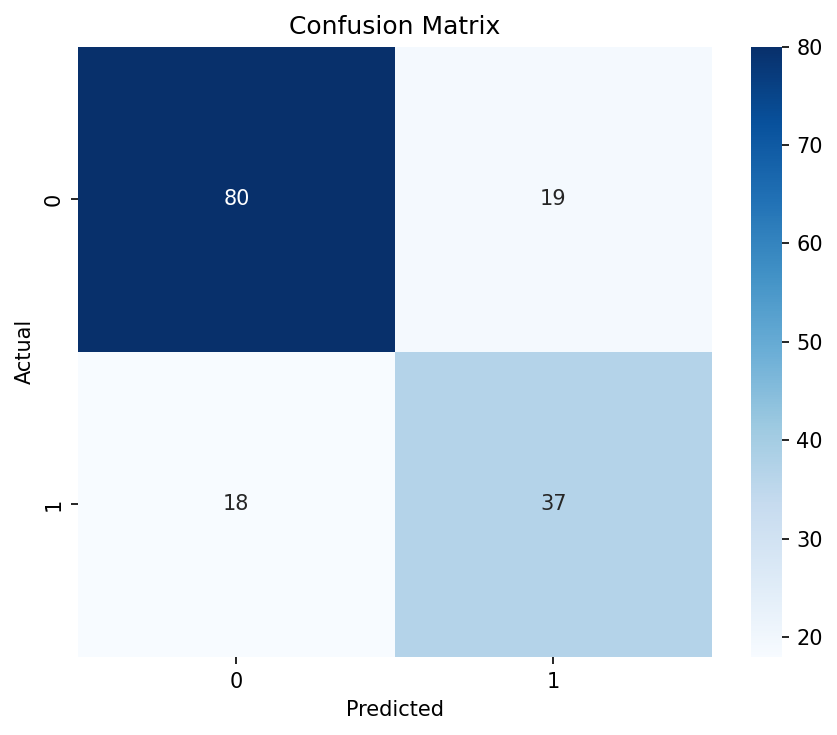

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# Generate the confusion matrix and visualize using heatmap
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [8]:
# Test prediction on a new patient record: Age=21, BMI=35.7, BloodPressure=75.0, Insulin=102.5, Glucose=112, DiabetesPedigreeFunction=0.148
sample_patient = pd.DataFrame(
    [[21, 35.7, 75.0, 102.5, 112, 0.148]],
    columns=['Age', 'BMI', 'BloodPressure', 'Insulin', 'Glucose', 'DiabetesPedigreeFunction']
)

sample_pred = model.predict(sample_patient)[0]
sample_prob = model.predict_proba(sample_patient)[0][1]

print(f"Predicted Outcome: {sample_pred} ({'Diabetic' if sample_pred == 1 else 'Non-Diabetic'})")
print(f"Predicted Probability of Diabetes: {sample_prob:.4f}")

Predicted Outcome: 0 (Non-Diabetic)
Predicted Probability of Diabetes: 0.1479


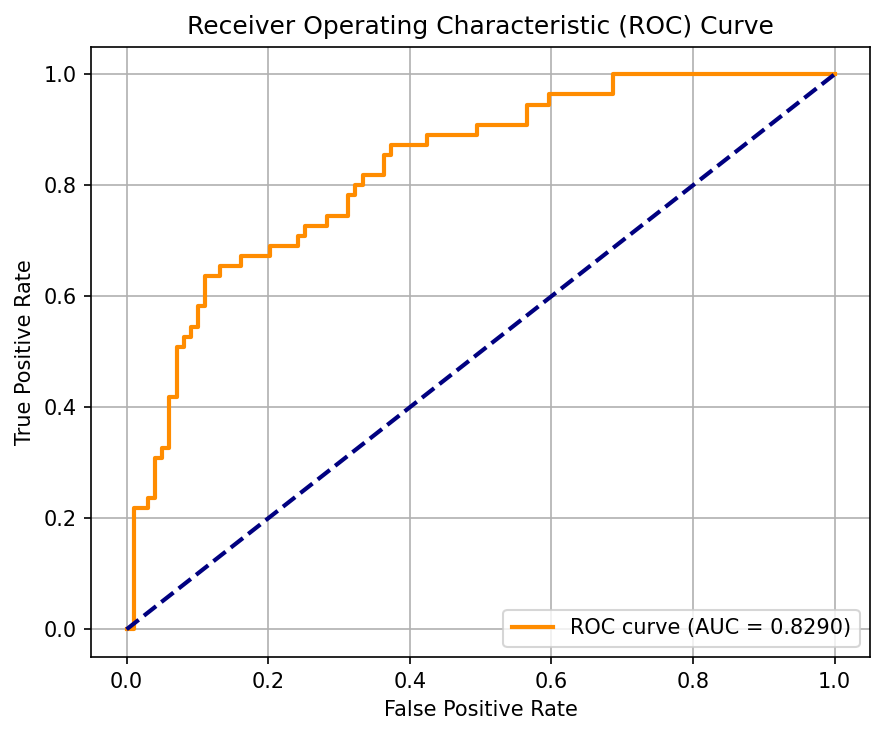

In [9]:
# Plot ROC Curve and calculate AUC
y_prob = model.predict_proba(X_test)[:, 1]
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()